# CALCE CX2 — LSTM vs Physics-Guided LSTM (Notebook Baseline)

**Purpose:** Train two models from `train.csv` and compare on a battery-disjoint validation/test split. Includes data verification, training, reproducible metrics, graphs, and saved outputs. **No external `.py` script is required.**

**Scientific qualification:** The PINN model applies a *soft monotonic-degradation prior* between truly consecutive retained cycles. This is a physics-**guided** LSTM, **not** a differential-equation-constrained electrochemical PINN. Actual capacity measurements can fluctuate or exhibit apparent recovery, so this prior may hurt performance. Only the validation split is used for early stopping; the test split is evaluated after training. These are in-dataset held-out cells, not external validation.


## 1 · Install packages (run once)

In [1]:
%pip install numpy pandas matplotlib scikit-learn torch

Note: you may need to restart the kernel to use updated packages.


## 2 · Imports, configuration, and locating the uploaded dataset

Either extract your ZIP next to the notebook, or set `DATA_DIR` to the extracted folder. If the ZIP is present alongside the notebook, this cell extracts it automatically.

In [2]:
import os, json, time, random, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# CHANGE THIS ONLY IF DATA IS STORED SOMEWHERE ELSE
DATA_DIR = None  # e.g. r"C:\Projects\battery-soh-prediction\data\processed"
ZIP_FILE = Path('pre processed ready to use data.zip')
OUT_DIR = Path('notebook_lstm_pinn_results')
OUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
SEQUENCE_LENGTH = 12
HIDDEN = 64
NUM_LAYERS = 1
DROPOUT = 0.1
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 80
PATIENCE = 15
PHYSICS_WEIGHT = 0.5
SEEDS = [42]  # for stronger paper results change to [42, 123, 2026]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch:', torch.__version__, '| Device:', DEVICE)
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))

if DATA_DIR is None:
    candidates = [Path('.'), Path('pre processed ready to use data'), Path('_calce_extracted/pre processed ready to use data')]
    if not any((p/'train.csv').exists() for p in candidates) and ZIP_FILE.exists():
        with zipfile.ZipFile(ZIP_FILE) as zf:
            zf.extractall('.')
    DATA_DIR = next((p for p in candidates if (p/'train.csv').exists()), None)
else:
    DATA_DIR = Path(DATA_DIR)
if DATA_DIR is None:
    raise FileNotFoundError('Could not locate train.csv. Extract the ZIP and set DATA_DIR in cell 2.')
print('Reading data from:', DATA_DIR.resolve())

Torch: 2.11.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Reading data from: C:\Projects\Battery_Soh\pre processed ready to use data


## 3 · Read and audit CSV splits

In [3]:
def read_split(filename):
    df = pd.read_csv(DATA_DIR / filename, parse_dates=['cycle_start'])
    needed = ['battery','cycle_ordinal','cycle_start','soh'] + FEATURES
    missing = sorted(set(needed)-set(df.columns))
    if missing: raise ValueError(f'{filename} missing columns: {missing}')
    if df[needed].isna().any().any(): raise ValueError(f'{filename} contains missing values')
    if df.duplicated(['battery','cycle_ordinal']).any(): raise ValueError(f'{filename} has duplicated battery+cycle')
    if not np.isfinite(df[FEATURES+['soh']].to_numpy(float)).all(): raise ValueError('Non-finite inputs')
    return df.sort_values(['battery','cycle_ordinal']).reset_index(drop=True)

splits = {name: read_split(f'{name}.csv') for name in ('train','validation','test')}
sets = {name: set(df.battery.unique()) for name,df in splits.items()}
assert not (sets['train']&sets['validation'] or sets['train']&sets['test'] or sets['validation']&sets['test']), 'Battery leakage!'
for name,df in splits.items():
    print(name, len(df), 'cycles | batteries:', sorted(df.battery.unique()))
print('\nTraining correlations with SOH:')
print(splits['train'][FEATURES+['soh']].corr(method='pearson')['soh'].drop('soh').sort_values(ascending=False).round(4))

train 7790 cycles | batteries: ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation 1743 cycles | batteries: ['CX2_36']
test 1477 cycles | batteries: ['CX2_38']

Training correlations with SOH:
cc_duration_s      0.9957
ic_peak_width     -0.7213
cv_duration_s     -0.7760
dva_peak          -0.7954
ic_peak_voltage   -0.8144
Name: soh, dtype: float64


## 4 · Training-only normalization and visual exploration

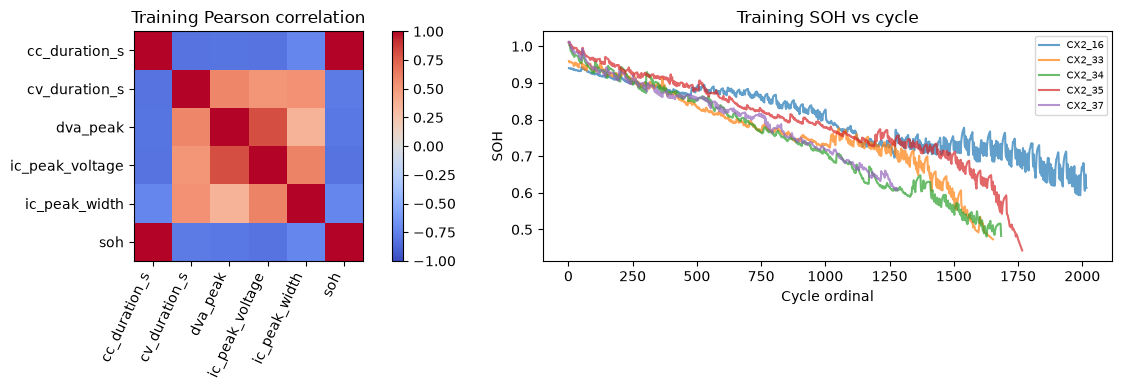

In [4]:
mean = splits['train'][FEATURES].mean().to_numpy(np.float32)
std = splits['train'][FEATURES].std(ddof=0).to_numpy(np.float32)
std = np.maximum(std, 1e-8)
(OUT_DIR/'scaler.json').write_text(json.dumps({'features':FEATURES,'mean':mean.tolist(),'std':std.tolist()},indent=2))

fig,axs = plt.subplots(1,2,figsize=(13,4))
corr=splits['train'][FEATURES+['soh']].corr()
im=axs[0].imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
axs[0].set_xticks(range(len(corr)), corr.columns,rotation=65,ha='right')
axs[0].set_yticks(range(len(corr)),corr.columns)
fig.colorbar(im,ax=axs[0]);axs[0].set_title('Training Pearson correlation')
for b,g in splits['train'].groupby('battery'):
    axs[1].plot(g.cycle_ordinal,g.soh,alpha=.7,label=b)
axs[1].set(title='Training SOH vs cycle',xlabel='Cycle ordinal',ylabel='SOH');axs[1].legend(fontsize=7)
plt.tight_layout();plt.show()

## 5 · Build sequence windows

The target for each window is **current-cycle SOH** (rather than a true future-cycle forecast). Past features and the current cycle's charging features are inputs. The model therefore estimates SOH after those charging measurements are available.

Windows remain inside one battery and never bridge missing cycle ordinals. Short windows receive **left-zero padding**. For the physics loss, a separate valid *previous-cycle window* is constructed only when the immediately previous retained cycle exists, avoiding false transitions at gaps. The zero padding does not represent measured rest.

In [5]:
class CycleWindows(Dataset):
    def __init__(self, df, seq_len, mean, std):
        xx=[]; pp=[]; yy=[]; valid=[]; meta=[]
        for battery,g in df.groupby('battery',sort=False):
            g = g.sort_values('cycle_ordinal').reset_index(drop=True)
            values = ((g[FEATURES].to_numpy(np.float32)-mean)/std)
            ords = g.cycle_ordinal.to_numpy()
            ys = g.soh.to_numpy(np.float32)
            for end in range(len(g)):
                start=end
                while start>0 and end-start+1<seq_len and ords[start]-ords[start-1]==1:
                    start-=1
                current = np.zeros((seq_len,len(FEATURES)),dtype=np.float32)
                cur_values = values[start:end+1]
                current[-len(cur_values):] = cur_values
                prev = np.zeros_like(current)
                consecutive = end>0 and (ords[end]-ords[end-1]==1)
                if consecutive:
                    prev_start=end-1
                    while prev_start>0 and (end-1)-prev_start+1<seq_len and ords[prev_start]-ords[prev_start-1]==1:
                        prev_start-=1
                    prev_values=values[prev_start:end]
                    prev[-len(prev_values):]=prev_values
                xx.append(current);pp.append(prev);yy.append(ys[end]);valid.append(consecutive)
                meta.append((battery,int(ords[end]),str(g.cycle_start.iloc[end])))
        self.x=torch.from_numpy(np.stack(xx));self.prev=torch.from_numpy(np.stack(pp))
        self.y=torch.tensor(yy,dtype=torch.float32)
        self.valid=torch.tensor(valid,dtype=torch.bool)
        self.meta=pd.DataFrame(meta,columns=['battery','cycle_ordinal','cycle_start'])
    def __len__(self): return len(self.y)
    def __getitem__(self,i): return self.x[i],self.prev[i],self.y[i],self.valid[i]

DSETS={k:CycleWindows(df,SEQUENCE_LENGTH,mean,std) for k,df in splits.items()}
for name,ds in DSETS.items():
    print(f'{name}: {len(ds)} windows; {ds.valid.sum().item()} confirmed consecutive predecessors')

train: 7790 windows; 7340 confirmed consecutive predecessors
validation: 1743 windows; 1645 confirmed consecutive predecessors
test: 1477 windows; 1385 confirmed consecutive predecessors


## 6 · Standard LSTM architecture and soft degradation prior

In [6]:
class LSTMRegressor(nn.Module):
    def __init__(self, n_features=5, hidden=64, layers=1, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, num_layers=layers, batch_first=True,
                            dropout=(dropout if layers>1 else 0))
        self.head = nn.Sequential(nn.Linear(hidden,32),nn.ReLU(),nn.Dropout(dropout),nn.Linear(32,1))
    def forward(self,x):
        _,(h,_) = self.lstm(x)
        return self.head(h[-1]).squeeze(-1)

# Physics-guided regularizer, for valid adjacent observations:
# L_physics = mean(ReLU(SOH_hat(current) - SOH_hat(previous))**2)
# This prior favors non-increasing predictions. It does not encode degradation kinetics,
# temperature or current effects; apparent recovery can violate the prior.

def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def compute_metrics(actual,pred):
    actual=np.asarray(actual);pred=np.asarray(pred)
    return {'rmse':float(np.sqrt(np.mean((pred-actual)**2))),
            'mae':float(np.mean(np.abs(pred-actual))),
            'mape_pct':float(100*np.mean(np.abs(pred-actual)/np.maximum(np.abs(actual),1e-8))),
            'r2':float(r2_score(actual,pred)), 'n':int(len(actual))}

@torch.no_grad()
def evaluate(model,ds):
    model.eval();preds=[]
    for x,_,_,_ in DataLoader(ds,batch_size=BATCH_SIZE,shuffle=False):
        preds.append(model(x.to(DEVICE)).cpu().numpy())
    return np.concatenate(preds)


## 7 · Train both baselines with early stopping (validation only)

In [7]:
def train_model(model_name,seed):
    seed_everything(seed)
    model=LSTMRegressor(len(FEATURES),HIDDEN,NUM_LAYERS,DROPOUT).to(DEVICE)
    optim=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
    train_loader=DataLoader(DSETS['train'],batch_size=BATCH_SIZE,shuffle=True)
    best_rmse=float('inf');best_epoch=0;epochs_bad=0;history=[]
    ckpt=OUT_DIR/f'{model_name}_seed{seed}.pt'
    start=time.perf_counter()
    for epoch in range(1,MAX_EPOCHS+1):
        model.train();epoch_fit=[];epoch_phys=[];epoch_total=[]
        for x,prev,y,valid in train_loader:
            x=x.to(DEVICE);prev=prev.to(DEVICE);y=y.to(DEVICE);valid=valid.to(DEVICE)
            optim.zero_grad()
            yp=model(x)
            fit=(yp-y).square().mean()
            phys=yp.new_zeros(())
            if model_name=='lstm_pinn' and valid.any().item():
                # IMPORTANT: Previous windows come from actual previous cycles,
                # not a zero-padded shifting trick.
                pprev=model(prev[valid])
                phys=torch.relu(yp[valid]-pprev).square().mean()
            loss=fit + (PHYSICS_WEIGHT*phys if model_name=='lstm_pinn' else 0)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optim.step()
            epoch_fit.append(fit.item());epoch_phys.append(phys.item());epoch_total.append(loss.item())
        validation_pred=evaluate(model,DSETS['validation'])
        vrmse=compute_metrics(DSETS['validation'].y.numpy(),validation_pred)['rmse']
        history.append({'epoch':epoch,'train_loss':np.mean(epoch_total),'train_mse':np.mean(epoch_fit),
                        'physics_loss':np.mean(epoch_phys),'validation_rmse':vrmse})
        if vrmse<best_rmse-1e-6:
            best_rmse=vrmse;best_epoch=epoch;epochs_bad=0
            torch.save({'state_dict':model.state_dict(),'features':FEATURES,'seed':seed,
                        'model_name':model_name,'best_epoch':best_epoch},ckpt)
        else:
            epochs_bad+=1
        if epoch==1 or epoch%10==0:
            print(f'{model_name} seed={seed} epoch={epoch:03d} train_MSE={np.mean(epoch_fit):.6f} val_RMSE={vrmse:.5f}')
        if epochs_bad>=PATIENCE:
            print('Early stopping at',epoch);break
    # Load ONLY the best-on-validation checkpoint
    try: saved=torch.load(ckpt,map_location=DEVICE,weights_only=True)
    except TypeError: saved=torch.load(ckpt,map_location=DEVICE)
    model.load_state_dict(saved['state_dict'])
    pd.DataFrame(history).to_csv(OUT_DIR/f'{model_name}_seed{seed}_history.csv',index=False)
    return model,{'best_epoch':best_epoch,'train_seconds':round(time.perf_counter()-start,2)},pd.DataFrame(history)

MODELS={};HISTORIES={};RESULTS=[]
# Test is NOT used for hyperparameter selection. It is evaluated only after
# each model has been selected by validation RMSE.
for seed in SEEDS:
    for model_name in ('lstm','lstm_pinn'):
        model,info,history=train_model(model_name,seed)
        MODELS[(model_name,seed)]=model
        HISTORIES[(model_name,seed)]=history
        for split_name,ds in DSETS.items():
            pred=evaluate(model,ds)
            actual=ds.y.numpy()
            RESULTS.append({'model':model_name,'seed':seed,'split':split_name,
                            **compute_metrics(actual,pred),**info})
            table=ds.meta.copy()
            table['soh_true']=actual;table['soh_pred']=pred;table['error']=pred-actual
            table.to_csv(OUT_DIR/f'{model_name}_seed{seed}_{split_name}_predictions.csv',index=False)
results=pd.DataFrame(RESULTS)
results.to_csv(OUT_DIR/'metrics.csv',index=False)
print('\nMetrics (SOH fraction; multiply RMSE/MAE by 100 for SOH percentage points):')
display(results.round(5))

lstm seed=42 epoch=001 train_MSE=0.084818 val_RMSE=0.03946
lstm seed=42 epoch=010 train_MSE=0.002296 val_RMSE=0.01981
lstm seed=42 epoch=020 train_MSE=0.001932 val_RMSE=0.01347
lstm seed=42 epoch=030 train_MSE=0.001507 val_RMSE=0.00952
lstm seed=42 epoch=040 train_MSE=0.001080 val_RMSE=0.00932
lstm seed=42 epoch=050 train_MSE=0.000765 val_RMSE=0.00875
lstm seed=42 epoch=060 train_MSE=0.000471 val_RMSE=0.00998
Early stopping at 60
lstm_pinn seed=42 epoch=001 train_MSE=0.084841 val_RMSE=0.03820
lstm_pinn seed=42 epoch=010 train_MSE=0.002152 val_RMSE=0.01660
lstm_pinn seed=42 epoch=020 train_MSE=0.001676 val_RMSE=0.01207
lstm_pinn seed=42 epoch=030 train_MSE=0.001203 val_RMSE=0.00930
lstm_pinn seed=42 epoch=040 train_MSE=0.000829 val_RMSE=0.01207
lstm_pinn seed=42 epoch=050 train_MSE=0.000476 val_RMSE=0.00918
lstm_pinn seed=42 epoch=060 train_MSE=0.000351 val_RMSE=0.01643
Early stopping at 62

Metrics (SOH fraction; multiply RMSE/MAE by 100 for SOH percentage points):


,model,seed,split,rmse,mae,mape_pct,r2,n,best_epoch,train_seconds
0,lstm,42,train,0.00594,0.00451,0.60639,0.99724,7790,45,22.00
1,lstm,42,validation,0.00582,0.00401,0.58274,0.99786,1743,45,22.00
2,lstm,42,test,0.01157,0.01069,1.45792,0.99228,1477,45,22.00
3,lstm_pinn,42,train,0.00586,0.00409,0.56374,0.99730,7790,47,33.17
4,lstm_pinn,42,validation,0.00706,0.00441,0.66659,0.99685,1743,47,33.17
5,lstm_pinn,42,test,0.01352,0.01266,1.73099,0.98946,1477,47,33.17


## 8 · Plot validation learning curves

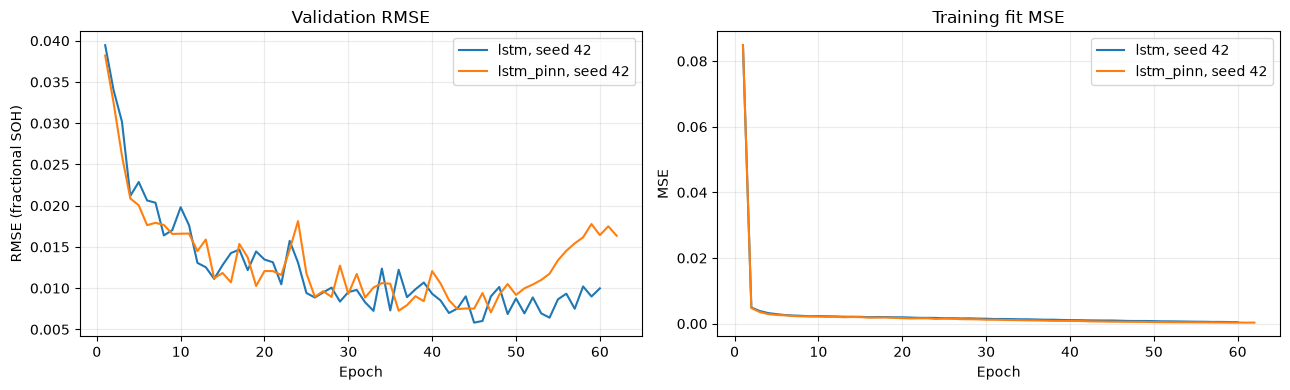

In [8]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for (name,seed),h in HISTORIES.items():
    axs[0].plot(h.epoch,h.validation_rmse,label=f'{name}, seed {seed}')
    axs[1].plot(h.epoch,h.train_mse,label=f'{name}, seed {seed}')
axs[0].set(title='Validation RMSE',xlabel='Epoch',ylabel='RMSE (fractional SOH)')
axs[1].set(title='Training fit MSE',xlabel='Epoch',ylabel='MSE')
for ax in axs: ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT_DIR/'learning_curves.png',dpi=160);plt.show()

## 9 · Plot battery-by-battery predictions on held-out test set

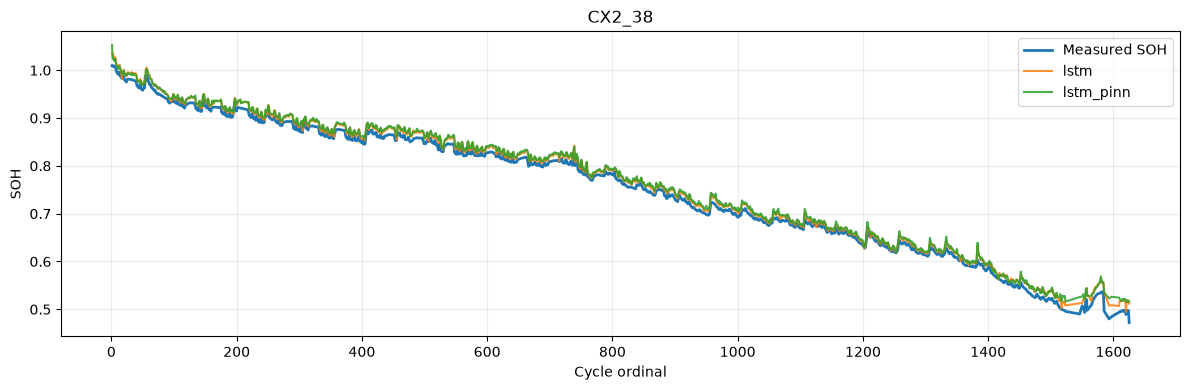

In [9]:
selected_seed=SEEDS[0]
fig,axes=plt.subplots(len(splits['test'].battery.unique()),1,
                      figsize=(12,max(4,3*len(splits['test'].battery.unique()))),squeeze=False)
for ax,battery in zip(axes.flat,sorted(splits['test'].battery.unique())):
    reference=DSETS['test'].meta.copy()
    mask=(reference.battery==battery).to_numpy()
    xs=reference.loc[mask,'cycle_ordinal'].to_numpy()
    ax.plot(xs,DSETS['test'].y.numpy()[mask],label='Measured SOH',lw=2)
    for model_name in ('lstm','lstm_pinn'):
        pp=evaluate(MODELS[(model_name,selected_seed)],DSETS['test'])
        ax.plot(xs,pp[mask],label=model_name,alpha=.85)
    ax.set(title=battery,xlabel='Cycle ordinal',ylabel='SOH');ax.legend();ax.grid(alpha=.25)
plt.tight_layout();plt.savefig(OUT_DIR/'test_predictions.png',dpi=160);plt.show()

## 10 · Compare RMSE by battery and summarize results

In [10]:
records=[]
for seed in SEEDS:
    for name in ('lstm','lstm_pinn'):
        p=pd.read_csv(OUT_DIR/f'{name}_seed{seed}_test_predictions.csv')
        for battery,g in p.groupby('battery'):
            records.append({'model':name,'seed':seed,'battery':battery,
                            **compute_metrics(g.soh_true,g.soh_pred)})
per_battery=pd.DataFrame(records)
per_battery.to_csv(OUT_DIR/'test_per_battery_metrics.csv',index=False)
display(per_battery.round(5))
print('All test summaries:')
display(results.query("split == 'test'").round(5))
if len(SEEDS)>1:
    display(results.query("split == 'test'").groupby('model')[['rmse','mae','mape_pct','r2']].agg(['mean','std']).round(5))

,model,seed,battery,rmse,mae,mape_pct,r2,n
0,lstm,42,CX2_38,0.01157,0.01069,1.45792,0.99228,1477
1,lstm_pinn,42,CX2_38,0.01352,0.01266,1.73099,0.98946,1477


All test summaries:


,model,seed,split,rmse,mae,mape_pct,r2,n,best_epoch,train_seconds
2,lstm,42,test,0.01157,0.01069,1.45792,0.99228,1477,45,22.00
5,lstm_pinn,42,test,0.01352,0.01266,1.73099,0.98946,1477,47,33.17


## 11 · Save experiment configuration

In [11]:
config={'data_dir':str(DATA_DIR.resolve()),'features':FEATURES,'sequence_length':SEQUENCE_LENGTH,
        'hidden':HIDDEN,'layers':NUM_LAYERS,'dropout':DROPOUT,'batch_size':BATCH_SIZE,
        'lr':LEARNING_RATE,'weight_decay':WEIGHT_DECAY,'max_epochs':MAX_EPOCHS,
        'patience':PATIENCE,'physics_weight':PHYSICS_WEIGHT,'seeds':SEEDS,
        'device':str(DEVICE),'experiment':'current-cycle SOH regression',
        'physics_prior':'squared positive adjacent-cycle predicted SOH increase'}
(OUT_DIR/'config.json').write_text(json.dumps(config,indent=2))
print('Saved outputs to:', OUT_DIR.resolve())
print('Files:',len(list(OUT_DIR.iterdir())))

Saved outputs to: C:\Projects\Battery_Soh\notebook_lstm_pinn_results
Files: 16


## Interpretation and next experiments

- Compare LSTM vs PINN using **identical inputs, splits, and seed(s)**.
- A higher PINN test error is a legitimate outcome: the monotonically decreasing prior can conflict with noisy measurements and apparent recovery.
- Avoid claiming electrochemical PINN or recovery prediction from these results alone. Data between recorded cycles is not necessarily rest.
- For paper-quality evidence, run at least 3 seeds, physics weights `[0, 0.01, 0.1, 0.5, 1]`, and leave-one-battery-out evaluation. Select weights using validation cells only.
- The test cell is not a new external dataset, and CC duration may strongly predict capacity because of the charging protocol. Compare against a **CC-duration-only** baseline.


In [14]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Projects\Battery_Soh\pre processed ready to use data\train.csv")
df["cycle_start"] = pd.to_datetime(df["cycle_start"])

df = df.sort_values(["battery", "cycle_ordinal"]).copy()

group = df.groupby("battery")

df["delta_soh"] = group["soh"].diff()
df["cycle_gap"] = group["cycle_ordinal"].diff()
df["time_gap_h"] = (
    group["cycle_start"].diff().dt.total_seconds() / 3600
)

# Flag substantial jumps between retained records
suspicious = df[df["delta_soh"].abs() > 0.02].copy()

suspicious["jump_pp"] = suspicious["delta_soh"] * 100

display(
    suspicious[
        [
            "battery",
            "cycle_ordinal",
            "soh",
            "jump_pp",
            "cycle_gap",
            "time_gap_h",
            "source_identifiers"
        ]
    ].sort_values(
        "jump_pp",
        key=lambda x: x.abs(),
        ascending=False
    ).head(30)
)

suspicious.to_csv("suspicious_soh_jumps.csv", index=False)

,battery,cycle_ordinal,soh,jump_pp,cycle_gap,time_gap_h,source_identifiers
1205,CX2_16,1273,0.761781,5.818774,2.0,223.500000,CX2_16/CX2_16_3_27_12.xlsx::Channel_1-006
3666,CX2_34,303,0.925044,5.261735,1.0,574.757778,CX2_34/CX2_34_11_22_10.xlsx::Channel_1-001
1559,CX2_16,1649,0.693468,-4.869721,2.0,8.208611,CX2_16/CX2_16_6_19_12.xlsx::Channel_1-006
1852,CX2_16,1970,0.625153,-4.762365,1.0,4.121667,CX2_16/CX2_16_9_10_12.xlsx::Channel_1-006
4473,CX2_34,1171,0.671937,4.666953,2.0,373.536944,CX2_34/CX2_34_5_13_11.xlsx::Channel_1-001
1763,CX2_16,1871,0.649010,-4.477616,1.0,4.159167,CX2_16/CX2_16_8_20_12.xlsx::Channel_1-006
1840,CX2_16,1957,0.670885,4.337557,2.0,7.814722,CX2_16/CX2_16_8_30_12.xlsx::Channel_1-006
3369,CX2_33,1602,0.534604,4.273689,6.0,683.046389,CX2_33/CX2_33_11_28_11.xlsx::Channel_1-012
3164,CX2_33,1364,0.691118,4.251081,3.0,189.779722,CX2_33/CX2_33_9_13_11.xlsx::Channel_1-012
1590,CX2_16,1684,0.691978,-4.174597,2.0,6.368056,CX2_16/CX2_16_7_03_12.xlsx::Channel_1-006


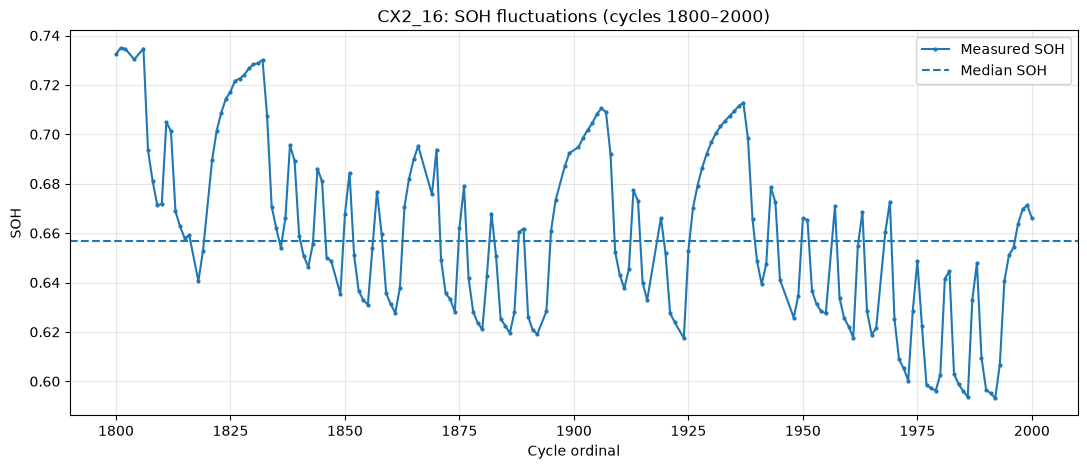

 cycle_ordinal      soh  delta_soh                        source_identifiers
          1800 0.732377        NaN CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1801 0.734941   0.002565 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1802 0.734684  -0.000257 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1804 0.730327  -0.004357 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1806 0.734717   0.004390 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1807 0.693470  -0.041248 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1808 0.681200  -0.012270 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1809 0.671498  -0.009702 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1810 0.671584   0.000086 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1811 0.704815   0.033232 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1812 0.701403  -0.003413 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006
          1813 0.668813  -0.032590 CX2_16/CX2_16_7_23_12.xlsx::Channel_1-006

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Projects\Battery_Soh\pre processed ready to use data\train.csv")

cell = df[df["battery"] == "CX2_16"].copy()
cell = cell.sort_values("cycle_ordinal")

region = cell[
    cell["cycle_ordinal"].between(1800, 2000)
].copy()

region["delta_soh"] = region["soh"].diff()

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    region["cycle_ordinal"],
    region["soh"],
    marker=".",
    markersize=4,
    label="Measured SOH"
)

ax.axhline(
    region["soh"].median(),
    linestyle="--",
    label="Median SOH"
)

ax.set_xlabel("Cycle ordinal")
ax.set_ylabel("SOH")
ax.set_title("CX2_16: SOH fluctuations (cycles 1800–2000)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print(
    region[
        ["cycle_ordinal", "soh", "delta_soh",
         "source_identifiers"]
    ].head(20).to_string(index=False)
)

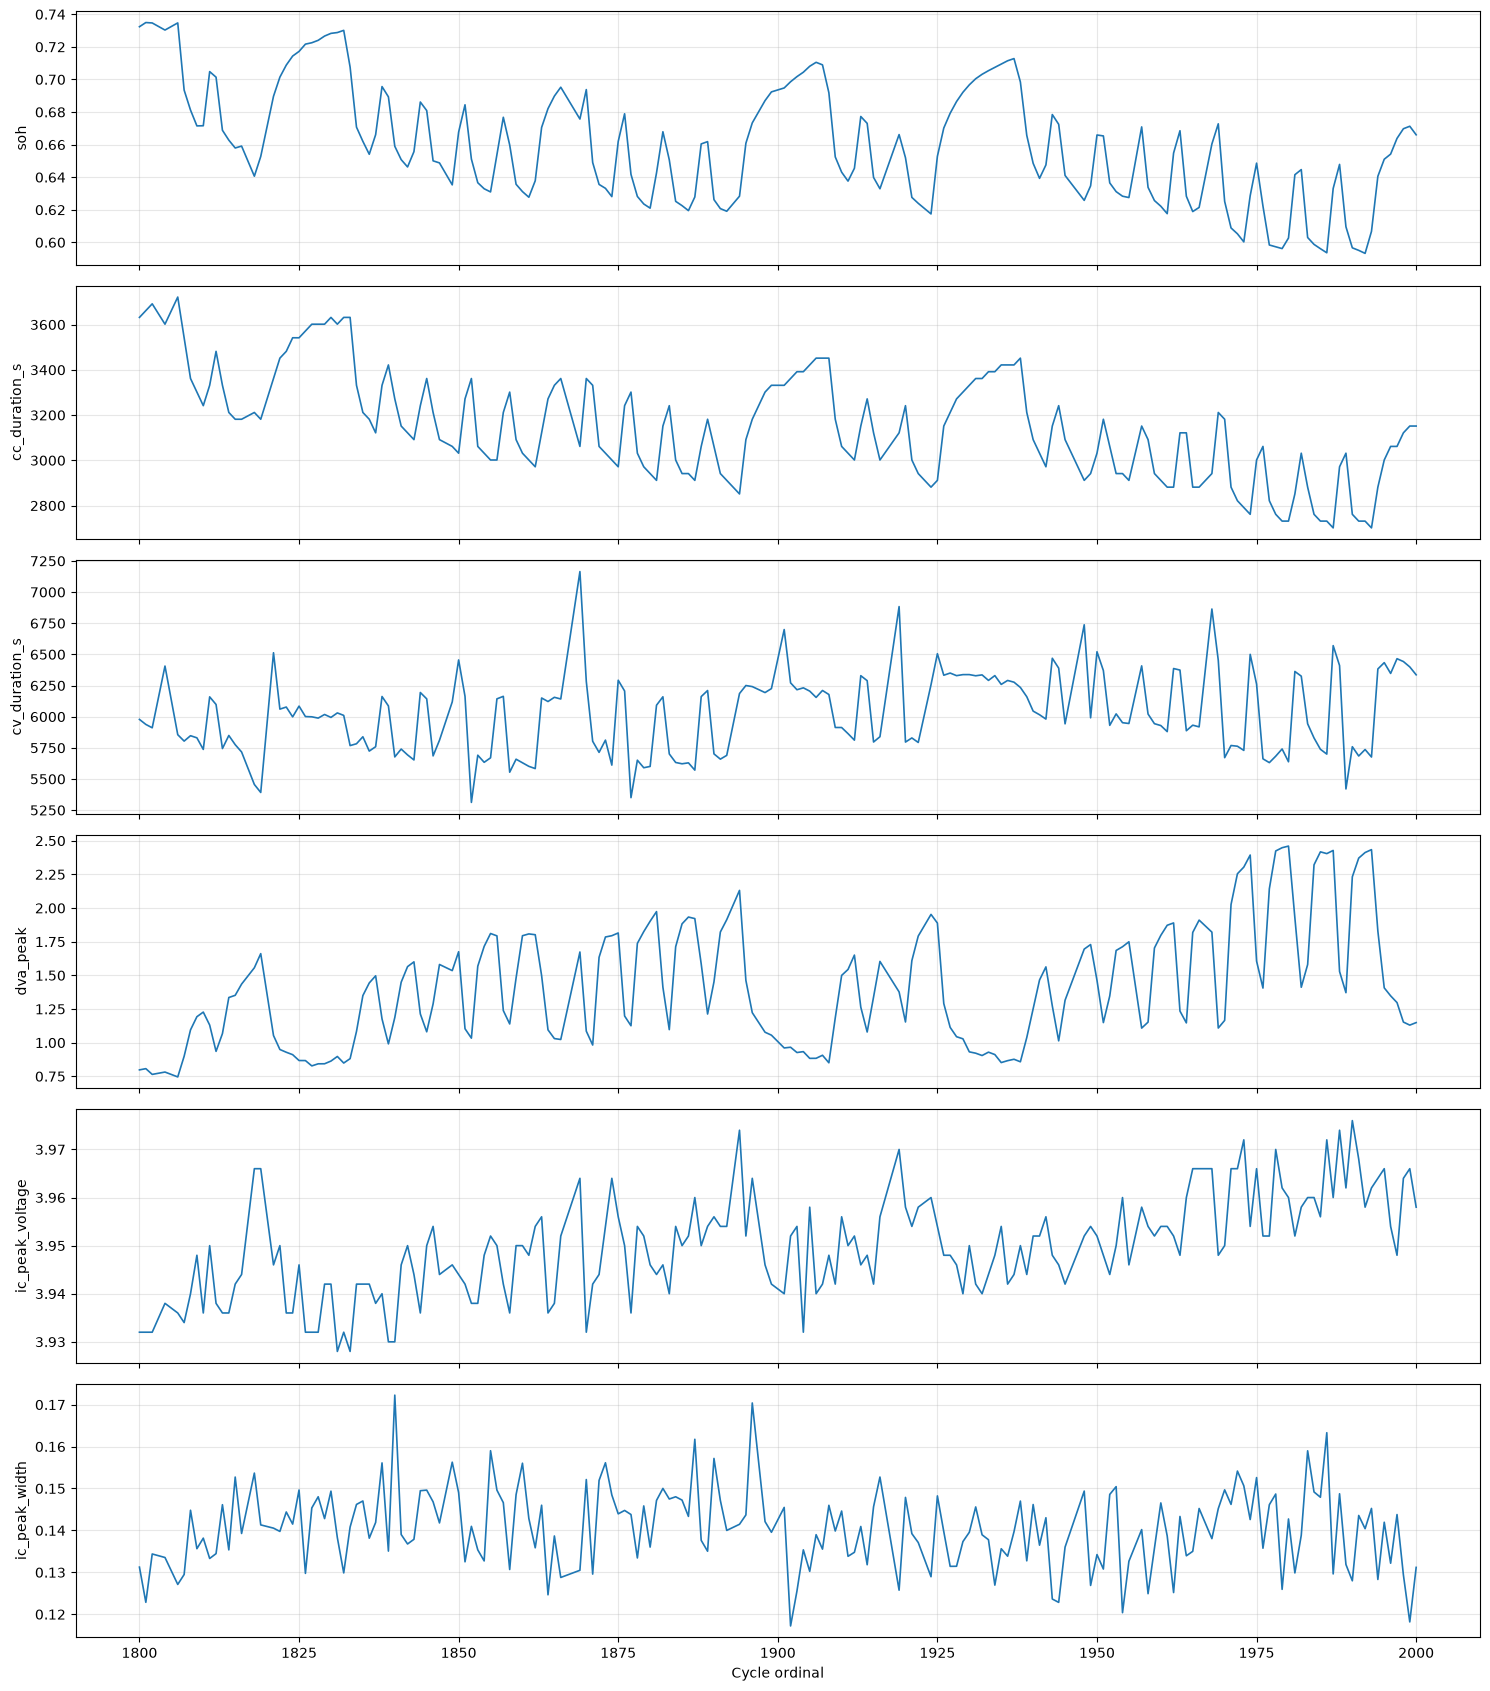

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Projects\Battery_Soh\pre processed ready to use data\train.csv")

cell = df[
    (df["battery"] == "CX2_16") &
    (df["cycle_ordinal"].between(1800, 2000))
].sort_values("cycle_ordinal")

features = [
    "soh",
    "cc_duration_s",
    "cv_duration_s",
    "dva_peak",
    "ic_peak_voltage",
    "ic_peak_width"
]

fig, axes = plt.subplots(
    len(features), 1,
    figsize=(15, 17),
    sharex=True
)

for ax, feature in zip(axes, features):
    ax.plot(
        cell["cycle_ordinal"],
        cell[feature],
        linewidth=1.2
    )
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Cycle ordinal")
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Projects\Battery_Soh\pre processed ready to use data\train.csv")
df = df.sort_values(["battery", "cycle_ordinal"]).copy()

g = df.groupby("battery")

df["d_soh"] = g["soh"].diff()
df["d_cc"] = g["cc_duration_s"].diff()
df["cycle_gap"] = g["cycle_ordinal"].diff()

# Only genuinely consecutive cycle ordinals
valid = df[df["cycle_gap"] == 1].copy()

print("Per-battery correlations of consecutive changes:\n")

for battery, part in valid.groupby("battery"):
    r = part["d_soh"].corr(part["d_cc"])
    print(f"{battery}: Pearson r = {r:.4f}, n = {len(part)}")

print("\nPooled correlation:")
print(valid["d_soh"].corr(valid["d_cc"]))

Per-battery correlations of consecutive changes:

CX2_16: Pearson r = 0.4555, n = 1805
CX2_33: Pearson r = 0.4001, n = 1392
CX2_34: Pearson r = 0.4151, n = 1447
CX2_35: Pearson r = 0.4279, n = 1530
CX2_37: Pearson r = 0.3776, n = 1166

Pooled correlation:
0.42793361498878696


In [22]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Projects\Battery_Soh\pre processed ready to use data\train.csv")
df["cycle_start"] = pd.to_datetime(df["cycle_start"])

df = df.sort_values(
    ["battery", "cycle_ordinal"]
).copy()

g = df.groupby("battery")

df["delta_soh"] = g["soh"].diff()
df["cycle_gap"] = g["cycle_ordinal"].diff()

df["time_gap_h"] = (
    g["cycle_start"].diff()
    .dt.total_seconds() / 3600
)

df["previous_source"] = (
    g["source_identifiers"].shift(1)
)

df["source_changed"] = (
    df["source_identifiers"] !=
    df["previous_source"]
)

# Flag changes above 2 percentage points
df["suspicious"] = df["delta_soh"].abs() > 0.02

# Classify transitions
df["transition_type"] = np.select(
    [
        df["cycle_gap"] > 1,
        df["time_gap_h"] > 24,
        df["source_changed"]
    ],
    [
        "Missing cycle ordinals",
        "Long time interval",
        "Source transition"
    ],
    default="Apparently continuous"
)

summary = (
    df[df["suspicious"]]
    .groupby(["battery", "transition_type"])
    .size()
    .unstack(fill_value=0)
)

display(summary)

df.to_csv("soh_audit.csv", index=False)

transition_type,Apparently continuous,Long time interval,Missing cycle ordinals
battery,,,
CX2_16,126,1,15
CX2_33,12,0,3
CX2_34,1,4,6
CX2_35,7,0,2
CX2_37,1,1,0


In [23]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Projects\Battery_Soh\pre processed ready to use data\train.csv")
df = df.sort_values(
    ["battery", "cycle_ordinal"]
).copy()

g = df.groupby("battery")

df["delta_soh"] = g["soh"].diff()
df["cycle_gap"] = g["cycle_ordinal"].diff()

# Only evaluate jumps between consecutive ordinals
df["large_jump"] = (
    (df["cycle_gap"] == 1) &
    (df["delta_soh"].abs() > 0.03)
)

# Flag both endpoints for investigation
df["previous_jump"] = (
    df.groupby("battery")["large_jump"]
      .shift(-1, fill_value=False)
)

df["quality_flag"] = (
    df["large_jump"] | df["previous_jump"]
)

# Save complete audit
df.to_csv("train_with_quality_flags.csv", index=False)

# Experimental filtered version only
filtered = df[~df["quality_flag"]].copy()

filtered.to_csv(
    "train_filtered_experimental.csv",
    index=False
)

print("Original samples:", len(df))
print("Filtered samples:", len(filtered))
print("Excluded samples:", len(df) - len(filtered))

Original samples: 7790
Filtered samples: 7690
Excluded samples: 100


In [25]:
import pandas as pd
import numpy as np
from pathlib import Path

# =====================================================
# 1. DATASET PATHS
# =====================================================

DATA_DIR = Path(
    r"C:\Projects\Battery_Soh\pre processed ready to use data"
)

INPUT_FILE = DATA_DIR / "train.csv"
OUTPUT_FILE = DATA_DIR / "train_final_filtered.csv"
AUDIT_FILE = DATA_DIR / "train_removed_cycles.csv"

# =====================================================
# 2. LOAD ORIGINAL DATA
# =====================================================

df = pd.read_csv(INPUT_FILE)

original_columns = df.columns.tolist()

df = df.sort_values(
    ["battery", "cycle_ordinal"]
).reset_index(drop=True)

print("Original samples:", len(df))

# =====================================================
# 3. DETECT ABRUPT SOH FLUCTUATIONS
# =====================================================

SOH_THRESHOLD = 0.03  # 3 percentage points

g = df.groupby("battery")

df["delta_soh"] = g["soh"].diff()
df["cycle_gap"] = g["cycle_ordinal"].diff()

# Flag jumps only between consecutive cycles
df["large_jump"] = (
    (df["cycle_gap"] == 1) &
    (df["delta_soh"].abs() > SOH_THRESHOLD)
)

# Flag the previous endpoint as well
df["previous_jump"] = (
    df.groupby("battery")["large_jump"]
    .shift(-1, fill_value=False)
)

df["remove_cycle"] = (
    df["large_jump"] | df["previous_jump"]
)

# =====================================================
# 4. SAVE REMOVED-CYCLE AUDIT
# =====================================================

removed = df[df["remove_cycle"]].copy()

removed.to_csv(AUDIT_FILE, index=False)

# =====================================================
# 5. CREATE FINAL TRAINING DATASET
# =====================================================

final_train = df[~df["remove_cycle"]].copy()

# Preserve original feature schema
final_train = final_train[original_columns]

final_train.to_csv(OUTPUT_FILE, index=False)

# =====================================================
# 6. DATASET SUMMARY
# =====================================================

print("\n========== FILTERING RESULTS ==========")
print("Original samples :", len(df))
print("Removed samples  :", len(removed))
print("Final samples    :", len(final_train))
print(
    "Removed percent  :",
    round(100 * len(removed) / len(df), 2), "%"
)

summary = pd.DataFrame({
    "Original": df.groupby("battery").size(),
    "Final": final_train.groupby("battery").size()
})

summary["Removed"] = (
    summary["Original"] - summary["Final"]
)

summary["Removed (%)"] = (
    100 * summary["Removed"] / summary["Original"]
).round(2)

display(summary)

print("\nSaved final training dataset:")
print(OUTPUT_FILE)

print("\nSaved removed-cycle audit:")
print(AUDIT_FILE)

Original samples: 7790

========== FILTERING RESULTS ==========
Original samples : 7790
Removed samples  : 100
Final samples    : 7690
Removed percent  : 1.28 %


,Original,Final,Removed,Removed (%)
battery,,,,
CX2_16,1899,1805,94,4.95
CX2_33,1488,1486,2,0.13
CX2_34,1554,1550,4,0.26
CX2_35,1630,1630,0,0.00
CX2_37,1219,1219,0,0.00



Saved final training dataset:
C:\Projects\Battery_Soh\pre processed ready to use data\train_final_filtered.csv

Saved removed-cycle audit:
C:\Projects\Battery_Soh\pre processed ready to use data\train_removed_cycles.csv
